In [1]:
# Import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load Dataset
df = pd.read_csv("housing.csv")

# Display first 5 rows
print("First 5 Rows:")
display(df.head())

# Dataset Shape
print("Dataset Shape:", df.shape)

# Dataset Information
print("\nDataset Information:")
df.info()

# Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

First 5 Rows:


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


Dataset Shape: (20640, 10)

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
med

In [2]:
# Dataset Shape
print("Dataset Shape:", df.shape)

# Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate Rows
print("\nDuplicate Rows:", df.duplicated().sum())

Dataset Shape: (20640, 10)

Missing Values:
longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64

Duplicate Rows: 0


In [3]:
# Handle Missing Values

median_bedrooms = df["total_bedrooms"].median()

df["total_bedrooms"] = df["total_bedrooms"].fillna(median_bedrooms)

# Check Missing Values Again
print("Missing Values After Cleaning:")
print(df.isnull().sum())

print("\nDataset Shape:", df.shape)

Missing Values After Cleaning:
longitude             0
latitude              0
housing_median_age    0
total_rooms           0
total_bedrooms        0
population            0
households            0
median_income         0
median_house_value    0
ocean_proximity       0
dtype: int64

Dataset Shape: (20640, 10)


In [4]:
# Separate Features and Target

X = df.drop("median_house_value", axis=1)
y = df["median_house_value"]

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features Shape: (20640, 9)
Target Shape: (20640,)

Feature Columns:
['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'ocean_proximity']


In [5]:
# Encode Categorical Column

X = pd.get_dummies(X, columns=["ocean_proximity"], dtype=int)

print("Features After Encoding:")
print(X.head())

print("\nNew Features Shape:", X.shape)

print("\nFeature Columns:")
print(X.columns.tolist())

Features After Encoding:
   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  ocean_proximity_<1H OCEAN  \
0       322.0       126.0         8.3252                          0   
1      2401.0      1138.0         8.3014                          0   
2       496.0       177.0         7.2574                          0   
3       558.0       219.0         5.6431                          0   
4       565.0       259.0         3.8462                          0   

   ocean_proximity_INLAND  ocean_proximity_ISLAND  ocean_proximity_NEAR BAY  \
0                 

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Feature Scaling
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Display Results
print("Training Features:", X_train_scaled.shape)
print("Testing Features:", X_test_scaled.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (16512, 13)
Testing Features: (4128, 13)
Training Target: (16512,)
Testing Target: (4128,)


In [7]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso

# Initialize Models
linear_model = LinearRegression()

ridge_model = Ridge(alpha=1.0)

lasso_model = Lasso(alpha=0.001, max_iter=10000)

# Train Models
linear_model.fit(X_train_scaled, y_train)

ridge_model.fit(X_train_scaled, y_train)

lasso_model.fit(X_train_scaled, y_train)

print("All three regression models trained successfully!")


All three regression models trained successfully!


C:\Users\Suman\AppData\Roaming\Python\Python313\site-packages\sklearn\linear_model\_coordinate_descent.py:716: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.441e+12, tolerance: 2.207e+10
  model = cd_fast.enet_coordinate_descent(


In [8]:
# Retrain Lasso with more iterations

lasso_model = Lasso(alpha=100, max_iter=50000, tol=0.001)

lasso_model.fit(X_train_scaled, y_train)

print("Lasso Regression trained successfully!")

Lasso Regression trained successfully!


In [9]:
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import numpy as np

# Predictions
y_pred_linear = linear_model.predict(X_test_scaled)
y_pred_ridge = ridge_model.predict(X_test_scaled)
y_pred_lasso = lasso_model.predict(X_test_scaled)

# Evaluation Function
def evaluate_model(name, y_true, y_pred):
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)

    print(f"\n{name}")
    print("RMSE:", round(rmse, 2))
    print("MAE:", round(mae, 2))
    print("R2 Score:", round(r2, 4))

# Evaluate All Models
evaluate_model("Linear Regression", y_test, y_pred_linear)
evaluate_model("Ridge Regression", y_test, y_pred_ridge)
evaluate_model("Lasso Regression", y_test, y_pred_lasso)


Linear Regression
RMSE: 70060.52
MAE: 50670.74
R2 Score: 0.6254

Ridge Regression
RMSE: 70057.43
MAE: 50668.13
R2 Score: 0.6255

Lasso Regression
RMSE: 69995.18
MAE: 50612.8
R2 Score: 0.6261


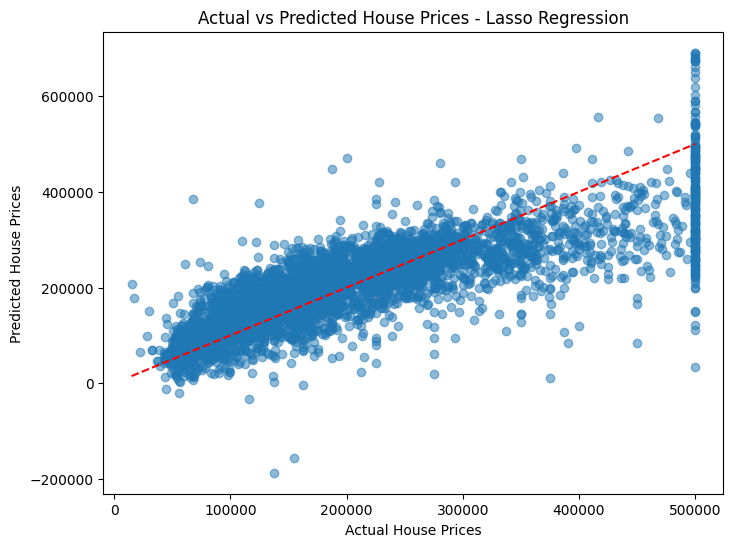

In [10]:
# Actual vs Predicted Values

plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred_lasso, alpha=0.5)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    "r--"
)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")
plt.title("Actual vs Predicted House Prices - Lasso Regression")

plt.show()

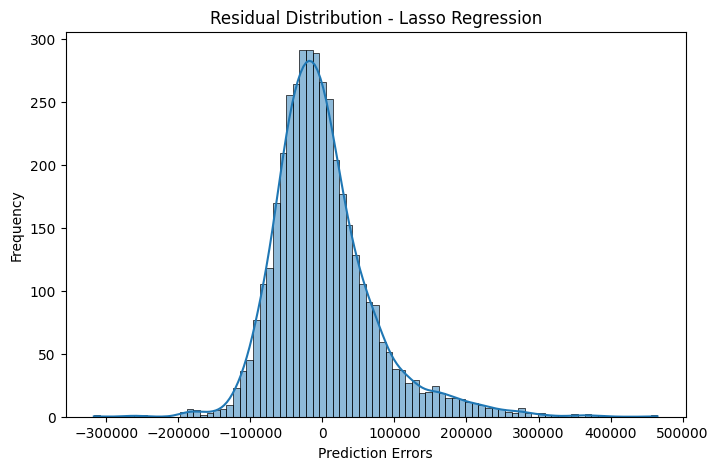

In [11]:
# Calculate Residuals
residuals = y_test - y_pred_lasso

# Residual Distribution Plot
plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Residual Distribution - Lasso Regression")
plt.xlabel("Prediction Errors")
plt.ylabel("Frequency")

plt.show()